# Trial Definition

Use this notebook **before** any analysis to:
1. Inspect the full raw LFP from one recording.
2. Identify and define trial windows (baseline / stimulation / post-stimulation).
3. Export clean trial `.h5` files ready for the analysis pipeline.

> **Run this notebook once per recording.** The output files drop straight into
> `data/processed/` and are picked up automatically by `batch_process_slices.py`.


In [5]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from src.config import load_config
from src.data_io import load_h5, list_h5_files
from src.preprocessing import select_channel

cfg = load_config()
print('Conditions:', cfg['conditions'])
print('Metrics:', cfg['metrics'])


Conditions: ['baseline', 'stimulation', 'post_stimulation']
Metrics: {'ci_soft': 0.95, 'ci_hard': 0.999}


## Load the full recording

In [6]:
# ← Point this to your raw (full-session) .h5 file
H5_FILES = list_h5_files(cfg['paths']['processed_dir'])
print('Available files:')
for f in H5_FILES:
    print(' ', os.path.basename(f))


Available files:
  20260414_Baseline_AC_Nathalia.h5
  20260414_Baseline_DC_Nathalia.h5
  20260414_Control_Nathalia.h5
  20260414_MESH_DC_2_Nathalia.h5
  20260414_MESH_DC_Nathalia.h5
  20260414_SLICE2_MESH_DC_Nathalia.h5
  20260414_SLICE3_CONTROL_Nathalia.h5


In [7]:
H5_FILENAME = '20260414_SLICE3_CONTROL_Nathalia.h5'

H5_PATH = rf"C:\ETH\EVA\Brain slice stimulation\20260414_brain slices exp in BCN\Nathalia\h5_raw\{H5_FILENAME}"   # ← change index or hardcode path

data, meta = load_h5(H5_PATH)
fs  = meta['fs']
lfp = select_channel(data, cfg['preprocessing'])
t   = np.arange(len(lfp)) / fs

print(f'File     : {os.path.basename(H5_PATH)}')
print(f'Duration : {meta["duration_seconds"]:.1f} s')
print(f'Channels : {meta["n_channels"]}')
print(f'Fs       : {fs} Hz')


File     : 20260414_SLICE3_CONTROL_Nathalia.h5
Duration : 4033.3 s
Channels : 32
Fs       : 3125.0000000000005 Hz


## Inspect the full LFP — identify noise and trial boundaries

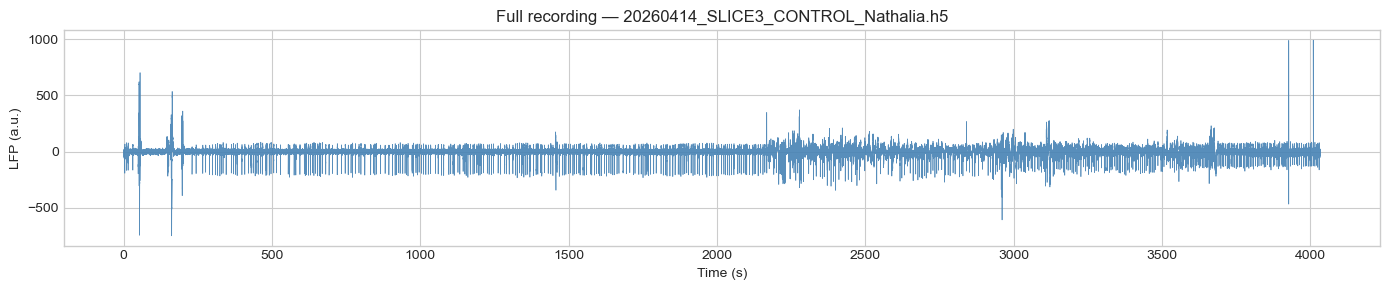


Look for:
  • Large transient spikes (artifacts) — note their time positions
  • Clear changes in oscillatory activity (trial start/end)
  • Quiet periods between trials



In [8]:
from src.visualization import plot_raw_lfp

fig, ax = plot_raw_lfp(lfp, fs, cfg)
ax.set_title(f'Full recording — {os.path.basename(H5_PATH)}')
plt.tight_layout()
plt.show()

print("""
Look for:
  • Large transient spikes (artifacts) — note their time positions
  • Clear changes in oscillatory activity (trial start/end)
  • Quiet periods between trials
""")


## Define trial windows

Two options:

**Option A — JSON file (recommended for reproducibility)**
Edit the JSON below, run the cell, then proceed to Step 5.

**Option B — Interactive GUI**
Run `python scripts/define_trials.py --slice <file> --interactive` in a terminal
(requires a display). Come back here after defining all trials.


In [9]:
# ── OPTION A: Define trials here in Python ───────────────────────────────
# Edit this list to match your recording.
# Times are in seconds relative to the START of the full recording.

from src.trial_io import TrialDefinition, ConditionWindow

trials = [
    TrialDefinition(
        label   = 'vitaly_trial_01',
        start_s = 2000.0,      # ← overall trial start
        end_s   = 2400.0,      # ← overall trial end
        conditions = [
            ConditionWindow('baseline',        start_s=2055.0, end_s=2100.0),
            ConditionWindow('stimulation',     start_s=2205.0, end_s=2250.0),
            ConditionWindow('post_stimulation',start_s=2300.0, end_s=2345.0),
        ]
    ),
    TrialDefinition(
    label='vitaly_trial_02', 
    start_s=2800.0, 
    end_s=3250, 
    conditions=[
            ConditionWindow('baseline',        start_s=2800.0, end_s=2900.0),
            ConditionWindow('stimulation',     start_s=3005.0, end_s=3105.0),
            ConditionWindow('post_stimulation',start_s=3150.0, end_s=3250.0),
    ]),
        TrialDefinition(
    label='vitaly_trial_03', 
    start_s=3400, 
    end_s=3800, 
    conditions=[
            ConditionWindow('baseline',        start_s=3400.0, end_s=3500.0),
            ConditionWindow('stimulation',     start_s=3550.0, end_s=3650.0),
            ConditionWindow('post_stimulation',start_s=3700.0, end_s=3800.0),
    ]),
]

print(f'Defined {len(trials)} trial(s):')
for t in trials:
    print(f'  {t.label}: {t.start_s}–{t.end_s} s  '
          f'({len(t.conditions)} condition windows)')


Defined 3 trial(s):
  vitaly_trial_01: 2000.0–2400.0 s  (3 condition windows)
  vitaly_trial_02: 2800.0–3250 s  (3 condition windows)
  vitaly_trial_03: 3400–3800 s  (3 condition windows)


## Preview the trial layout on the full recording

In [11]:
from src.visualization import plot_trial_overview

%matplotlib qt

fig, ax = plot_trial_overview(lfp, fs, trials, cfg)
plt.tight_layout()
plt.show()

# Check that the coloured windows cover the correct periods.
# Go back to Step 4 and adjust times if needed.


## Save clean trial windows

In [12]:
from scripts.define_trials import process_and_save

output_files = process_and_save(
    h5_path    = H5_PATH,
    trials     = trials,
    cfg        = cfg,
    output_dir = cfg['paths']['condition_dir'],
)

print(f'\n{len(output_files)} file(s) written:')
for f in output_files:
    print(' ', os.path.basename(f))



Processing trial 'vitaly_trial_01' (2000.0–2400.0 s)...
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_baseline.h5
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_stimulation.h5
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_post_stimulation.h5

Processing trial 'vitaly_trial_02' (2800.0–3250.0 s)...
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_baseline.h5
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_stimulation.h5
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation.h5

Processing trial 'vitaly_trial_03' (3400.0–3800.0 s)...
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_baseline.h5
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_stimulation.h5
  ✓ Saved → 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_post_stimulation.h5

Trial definitions saved → 20260414_SLICE3_CONTROL_Nathalia_trial_definitions.json

Done. 9 file(s) written to c:\ETH\EVA\Brain slice stimu

## Quick sanity check on one output file

In [13]:
from src.data_io import load_h5
from src.trial_io import load_trial_metadata

if output_files:
    check_path = output_files[0]
    check_data, check_meta = load_h5(check_path)
    trial_meta = load_trial_metadata(check_path)

    print(f'File    : {os.path.basename(check_path)}')
    print(f'Shape   : {check_data.shape}')
    print(f'Duration: {check_meta["duration_seconds"]:.2f} s')
    print(f'Trial metadata: {trial_meta}')

    # Quick LFP plot
    lfp_check = check_data.mean(axis=1)
    t_check   = np.arange(len(lfp_check)) / check_meta['fs']
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(t_check, lfp_check, lw=0.5, color='steelblue')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('LFP (a.u.)')
    ax.set_title(f'Cleaned trial: {os.path.basename(check_path)}')
    plt.tight_layout()
    plt.show()


File    : 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_baseline.h5
Shape   : (140625, 32)
Duration: 45.00 s
Trial metadata: {'artifact_fraction': np.float64(0.0), 'trial_label': 'vitaly_trial_01', 'source_file': '20260414_SLICE3_CONTROL_Nathalia.h5', 'trial_window_start_s': np.float64(2055.0), 'trial_window_end_s': np.float64(2100.0)}


## Next steps

The output `.h5` files are now in `data/processed/` and ready for analysis.

Proceed to:
- **`notebooks/01_exploratory.ipynb`** — inspect individual recordings
- **`notebooks/02_up_down_analysis.ipynb`** — run the full Up/Down analysis
- **`scripts/batch_process_slices.py`** — process all slices at once
